# Yambda 19 · Seed noise, and the w=1 / w=8 blend on test

Two questions left over from notebook 18:

1. **How noisy is the ranker?** Many of our differences are 1–3%. Each config is trained with 3 seeds
   (the seed controls row/feature subsampling and the early-stopping hold-out users).
2. **Does blending w=1 and w=8 hold up on test?** Same λ for every user:
   `score = (1 − m)·rank_pct(w=1) + m·rank_pct(w=8)`, set at serving time, no retraining.

**Fixed before looking at test:** the headline `m` is chosen on validation with the notebook-17 rule
(largest `m` whose mean overall recall@10 is within 5% of `w = 1`). On test we report the whole curve
and do not pick anything.

Candidates are cached; about 35 min (18 ranker fits).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from musicrec import config
from musicrec.preprocess import Split
from musicrec.evaluation import evaluate, paired_bootstrap, artist_novelty
from musicrec.yambda import load_item_artist, build_events
from musicrec import ranking as R

pd.set_option("display.float_format", "{:,.4f}".format)
OUT = config.PROJECT_ROOT / "reports" / "yambda"
CACHE = config.YAMBDA_DIR / "cands"
S4 = ["ials", "sasrec", "pop", "bpr"]
FEATS = R.feature_columns(S4, organic=True)
SEEDS = [42, 7, 2026]
GAINS = {"w=1": None, "w=2": [0, 1, 2], "w=8": [0, 1, 8]}
BLEND_MS = [0.25, 0.5, 0.75]
item_artist = load_item_artist()
events = build_events(min_played_ratio=50)

def build(tag, split):
    src = {s: pd.read_parquet(CACHE / f"{tag}_{s}.parquet") for s in S4}
    c = R.add_labels(R.merge_candidates(src), split)
    c = R.add_features(c, split, item_artist, S4)
    c = R.add_organic_features(c, split, events)
    c["rel"] = R.graded_relevance(c)
    return c

def evaluate_col(c, split, col, new_artist):
    m = R.PrecomputedScores(c[["user_idx", "item_idx", col]], split.n_items, col, col)
    r = evaluate(m, split, return_per_user=True)
    rn = evaluate(m, split, targets=split.targets[new_artist], return_per_user=True)
    return {"recall@10": r["recall@10"], "new-artist": rn["recall@10"], "hit_rate@10": r["hit_rate@10"],
            "per_user": r["per_user"], "per_user_new": rn["per_user"]}

def run(c_tr, c_ev, split, new_artist, seed):
    """Train w=1, w=2, w=8 with one seed, score c_ev, add the blends. Returns {config: metrics}."""
    out = {}
    for name, gain in GAINS.items():
        kw = {} if gain is None else {"label_col": "rel", "label_gain": gain}
        c_ev[name] = R.fit_ranker(c_tr, FEATS, seed=seed, **kw).predict(c_ev[FEATS])
        out[name] = evaluate_col(c_ev, split, name, new_artist)
    for m in BLEND_MS:
        col = f"blend m={m}"
        c_ev[col] = R.per_user_blend(c_ev, "w=1", "w=8", np.full(split.n_users, m))
        out[col] = evaluate_col(c_ev, split, col, new_artist)
    return out

ORDER = ["w=1", "w=2"] + [f"blend m={m}" for m in BLEND_MS] + ["w=8"]
def summarize(runs):
    rows = [{"seed": s, "config": n, "recall@10": r["recall@10"], "new-artist": r["new-artist"]}
            for s, res in runs.items() for n, r in res.items()]
    df = pd.DataFrame(rows)
    agg = df.groupby("config")[["recall@10", "new-artist"]].agg(["mean", "std", "min", "max"]).reindex(ORDER)
    return df, agg

## Candidates

In [2]:
rank, val, test = (Split.load(d) for d in (config.YAMBDA_SPLIT_RANK_DIR, config.YAMBDA_SPLIT_VAL_DIR, config.YAMBDA_SPLIT_TEST_DIR))
c_rank, c_val, c_test = build("rank", rank), build("val", val), build("test", test)
na_val, na_test = artist_novelty(val, item_artist), artist_novelty(test, item_artist)

## 1. Seed noise on validation (train on the earlier window)

In [3]:
runs_val = {}
for s in SEEDS:
    t0 = time.time()
    runs_val[s] = run(c_rank, c_val, val, na_val, s)
    print(f"seed {s}: " + "  ".join(f"{n} {r['recall@10']:.4f}" for n, r in runs_val[s].items()) + f"  ({time.time() - t0:.0f}s)")
df_val, agg_val = summarize(runs_val)
agg_val

seed 42: w=1 0.0524  w=2 0.0532  w=8 0.0498  blend m=0.25 0.0520  blend m=0.5 0.0522  blend m=0.75 0.0518  (231s)
seed 7: w=1 0.0527  w=2 0.0503  w=8 0.0497  blend m=0.25 0.0535  blend m=0.5 0.0526  blend m=0.75 0.0516  (123s)
seed 2026: w=1 0.0509  w=2 0.0525  w=8 0.0469  blend m=0.25 0.0525  blend m=0.5 0.0515  blend m=0.75 0.0506  (106s)


recall@10                      new-artist                     
                  mean    std    min    max       mean    std    min    max
config                                                                     
w=1             0.0520 0.0009 0.0509 0.0527     0.0176 0.0011 0.0164 0.0186
w=2             0.0520 0.0015 0.0503 0.0532     0.0242 0.0002 0.0240 0.0244
blend m=0.25    0.0527 0.0008 0.0520 0.0535     0.0233 0.0009 0.0224 0.0242
blend m=0.5     0.0521 0.0006 0.0515 0.0526     0.0266 0.0013 0.0253 0.0279
blend m=0.75    0.0513 0.0006 0.0506 0.0518     0.0298 0.0011 0.0286 0.0308
w=8             0.0488 0.0016 0.0469 0.0498     0.0330 0.0018 0.0311 0.0346

In [4]:
# Within one seed, is w=2 better than w=1? A difference that flips sign across seeds is noise.
d = df_val.pivot(index="seed", columns="config", values="recall@10")
pd.DataFrame({"w=2 − w=1": d["w=2"] - d["w=1"], "blend 0.5 − w=1": d["blend m=0.5"] - d["w=1"],
              "w=8 − w=1": d["w=8"] - d["w=1"]})

,w=2 − w=1,blend 0.5 − w=1,w=8 − w=1
seed,,,
7,-0.0024,-0.0001,-0.0030
42,0.0008,-0.0002,-0.0026
2026,0.0015,0.0005,-0.0040


In [5]:
# Headline m, fixed on validation before test: largest m with mean overall >= 95% of mean w=1
mean_val = agg_val[("recall@10", "mean")]
M = max(m for m in BLEND_MS if mean_val[f"blend m={m}"] >= 0.95 * mean_val["w=1"])
print("headline blend: m =", M)

headline blend: m = 0.75


## 2. Test (run once): rankers retrained on the validation window, same 3 seeds

In [6]:
runs_test = {}
for s in SEEDS:
    t0 = time.time()
    runs_test[s] = run(c_val, c_test, test, na_test, s)
    print(f"seed {s}: " + "  ".join(f"{n} {r['recall@10']:.4f}" for n, r in runs_test[s].items()) + f"  ({time.time() - t0:.0f}s)")
df_test, agg_test = summarize(runs_test)
print("seed 42 should match notebook 17: w=1 0.0529, w=2 0.0489")
agg_test

seed 42: w=1 0.0529  w=2 0.0489  w=8 0.0492  blend m=0.25 0.0513  blend m=0.5 0.0508  blend m=0.75 0.0501  (111s)
seed 7: w=1 0.0536  w=2 0.0505  w=8 0.0475  blend m=0.25 0.0530  blend m=0.5 0.0516  blend m=0.75 0.0502  (117s)
seed 2026: w=1 0.0509  w=2 0.0533  w=8 0.0488  blend m=0.25 0.0523  blend m=0.5 0.0525  blend m=0.75 0.0507  (126s)
seed 42 should match notebook 17: w=1 0.0529, w=2 0.0489


recall@10                      new-artist                     
                  mean    std    min    max       mean    std    min    max
config                                                                     
w=1             0.0525 0.0014 0.0509 0.0536     0.0186 0.0009 0.0177 0.0195
w=2             0.0509 0.0022 0.0489 0.0533     0.0241 0.0027 0.0220 0.0271
blend m=0.25    0.0522 0.0009 0.0513 0.0530     0.0238 0.0008 0.0231 0.0247
blend m=0.5     0.0517 0.0009 0.0508 0.0525     0.0270 0.0011 0.0260 0.0281
blend m=0.75    0.0503 0.0003 0.0501 0.0507     0.0292 0.0010 0.0286 0.0304
w=8             0.0485 0.0009 0.0475 0.0492     0.0319 0.0013 0.0304 0.0328

In [7]:
# Significance on seed 42 (paired bootstrap over users)
r = runs_test[42]
h = f"blend m={M}"
sig = pd.DataFrame({
    f"{h} vs w=1, overall":    paired_bootstrap(r["w=1"]["per_user"], r[h]["per_user"]),
    f"{h} vs w=1, new-artist": paired_bootstrap(r["w=1"]["per_user_new"], r[h]["per_user_new"]),
    f"{h} vs w=2, overall":    paired_bootstrap(r["w=2"]["per_user"], r[h]["per_user"]),
    f"{h} vs w=2, new-artist": paired_bootstrap(r["w=2"]["per_user_new"], r[h]["per_user_new"]),
}).T[["a", "b", "diff", "rel_diff", "ci_low", "ci_high", "p(b<=a)"]]
pd.concat({"val": agg_val, "test": agg_test}).to_csv(OUT / "ranker_seeds_blend.csv")
sig.to_csv(OUT / "final_test_blend_significance.csv")
sig

,a,b,diff,rel_diff,ci_low,ci_high,p(b<=a)
"blend m=0.75 vs w=1, overall",0.0529,0.0501,-0.0028,-0.0529,-0.0050,-0.0007,0.9955
"blend m=0.75 vs w=1, new-artist",0.0185,0.0286,0.0101,0.5464,0.0082,0.0121,0.0000
"blend m=0.75 vs w=2, overall",0.0489,0.0501,0.0012,0.0247,-0.0011,0.0036,0.1640
"blend m=0.75 vs w=2, new-artist",0.0220,0.0286,0.0066,0.3006,0.0046,0.0087,0.0000


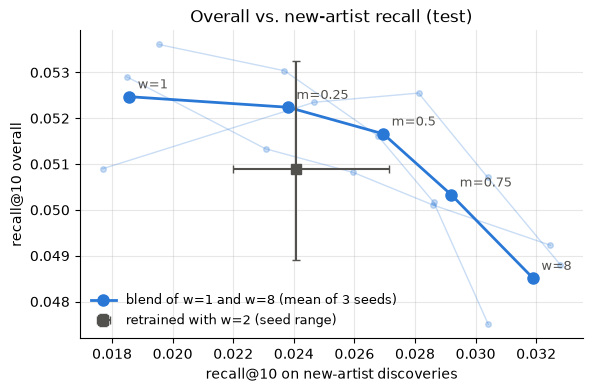

In [8]:
BLUE, GRAY = "#2a78d6", "#52514e"
fig, ax = plt.subplots(figsize=(6.5, 4))
curve = ["w=1"] + [f"blend m={m}" for m in BLEND_MS] + ["w=8"]
for s in SEEDS:                                                   # one faint line per seed
    ax.plot([runs_test[s][n]["new-artist"] for n in curve], [runs_test[s][n]["recall@10"] for n in curve],
            color=BLUE, lw=1, alpha=0.25, marker="o", markersize=4)
mx, my = agg_test.loc[curve, ("new-artist", "mean")], agg_test.loc[curve, ("recall@10", "mean")]
ax.plot(mx, my, color=BLUE, lw=2, marker="o", markersize=8, label="blend of w=1 and w=8 (mean of 3 seeds)")
for n, x, y in zip(curve, mx, my):
    ax.annotate(n.replace("blend ", ""), (x, y), textcoords="offset points", xytext=(6, 6), color=GRAY, fontsize=9)
w2 = agg_test.loc["w=2"]
ax.errorbar(w2[("new-artist", "mean")], w2[("recall@10", "mean")],
            xerr=[[w2[("new-artist", "mean")] - w2[("new-artist", "min")]], [w2[("new-artist", "max")] - w2[("new-artist", "mean")]]],
            yerr=[[w2[("recall@10", "mean")] - w2[("recall@10", "min")]], [w2[("recall@10", "max")] - w2[("recall@10", "mean")]]],
            color=GRAY, marker="s", markersize=7, capsize=3, ls="none", label="retrained with w=2 (seed range)")
ax.set(xlabel="recall@10 on new-artist discoveries", ylabel="recall@10 overall",
       title="Overall vs. new-artist recall (test)")
ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
fig.savefig(config.YAMBDA_FIGURES_DIR / "y19_blend_test.png", dpi=150, bbox_inches="tight")